In [1]:
import torch

import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

from lib_pca.distributional_pca import DistributionalPCA
from lib_pca.lifted_pca import LiftedPCA

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


## Dataset of Dirac

Only Diracs. Both Distributional PCA and Lifted PCA should coincide with usual PCA.

In [2]:
means = torch.randn((100, 2))
concat_samples = means - torch.mean(means, axis=0, keepdims=True)
samples = concat_samples[:,None]

## Different PCA

In [3]:
# PCA on the points
pca_means = PCA()
pca_means.fit(means)
eigenvectors_means = torch.from_numpy(pca_means.components_)

# Distributional PCA
pca_distributional_samples = DistributionalPCA()
pca_distributional_samples.fit_from_samples(concat_samples, torch.arange(len(means)))
eigenvectors_distributional_samples = pca_distributional_samples.components_

lifted_pca = LiftedPCA(n_components=1, n_samples=1)
lifted_pca.fit(samples)
eigenvectors_lifted_pca = lifted_pca.components_[:,:,0]

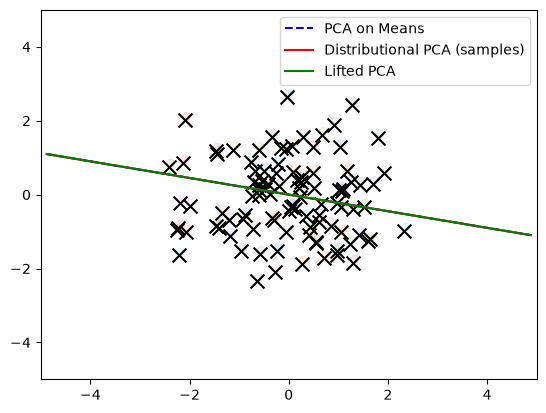

In [4]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    # draw_cov(means[k], Sigmas[k])

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

pc1_means = ts[:, None] * eigenvectors_means[0][None] # +  means.mean(axis=0, keepdims=True) 
plt.plot(pc1_means[:,0], pc1_means[:,1], "--", c="b", label="PCA on Means")

pc1_distributional_samples = ts[:, None] * eigenvectors_distributional_samples[0][None]
plt.plot(pc1_distributional_samples[:,0], pc1_distributional_samples[:,1], c="red", label="Distributional PCA (samples)")

pc1_lifted = ts[:, None] * eigenvectors_lifted_pca[0][None]
plt.plot(pc1_lifted[:,0], pc1_lifted[:,1], c="green", label="Lifted PCA")

plt.xlim(-5, 5)
plt.ylim(-5, 5)

plt.legend()
plt.show()